In [20]:
import numpy as np
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from scipy import constants

# Custom exception for constraint violations
class StigmaConstraintError(Exception):
    """Raised when Stigma theory constraints are violated"""
    pass

def validate_stigma_constraints(stigma, varpi_0):
    """
    Validate Stigma theory constraints for given parameters.
    
    Args:
        stigma: Stigma parameter value
        varpi_0: Initial varpi value (cpr)
        
    Raises:
        StigmaConstraintError: If constraints are not satisfied
    """
    constraint1 = stigma > varpi_0**2
    constraint2 = stigma * (5 + 4*stigma*(-2 + varpi_0**2)) < varpi_0**2
    
    if not constraint1:
        raise StigmaConstraintError(
            f"Constraint 1 violated: stigma ({stigma:.6f}) must be > varpi_0^2 ({varpi_0**2:.6f})"
        )
    
    if not constraint2:
        lhs = stigma * (5 + 4*stigma*(-2 + varpi_0**2))
        raise StigmaConstraintError(
            f"Constraint 2 violated: stigma*(5 + 4*stigma*(-2 + varpi_0^2)) = {lhs:.6f} must be < varpi_0^2 ({varpi_0**2:.6f})"
        )
    
    return True

#Equations
#Omega_r(radiation)
MP2 = 1
# /(8*constants.pi*constants.G)
# MP2 = 100
def omega_r(h):
    ab = (8*constants.pi**5*constants.k**4)/(15*constants.h**3*constants.c**3)
    rhor = ab*2.7255**4/(constants.c**2)
    rhov = 3.046*(7/8)*(4/11)**(4/3)*rhor
    return((rhor+rhov)/((3*(100*h)**2/(8*constants.pi*constants.G))*(1000)**2/(10**6*constants.parsec)**2))

#power series for a and cp(varpi)
def aseries(tau, cpr, omega_m, h,  OmL, a0, stigma, ups2):
    val = (
		((100*h)**2*omega_m*tau**2*(stigma**4 - 2*stigma**5 + 2*(-4 + stigma)*(-1 + 
		stigma)*stigma**3*cpr**2 + 2*stigma**2*(2 + stigma)*(-3 + 
		4*stigma)*cpr**4 + 2*stigma*(2 + stigma - 7*stigma**2)*cpr**6 + 
		(-1 + 4*stigma**2)*cpr**8))/(2*a0*ups2*cpr**2*(stigma**3*(5 + 
		stigma)*(-1 + 2*stigma) + 3*stigma**2*(8 + stigma*(-17 + 
		3*stigma))*cpr**2 - stigma*(11 + stigma + 2*stigma**2*(-30 + 
		stigma*(14 + stigma)))*cpr**4 + (-1 + 2*stigma)*(1 + 2*stigma)*(-2 
		+ 3*(-1 + stigma)*stigma)*cpr**6)) + 
		(2*(100*h)*tau*((omega_r(h)*stigma*(stigma - cpr**2))/(ups2*(5*stigma - 
		cpr**2 + 4*stigma**2*(-2 + cpr**2))))**(1/2))/(a0*cpr) + 
		((100*h)**3*omega_m**2*tau**3*(stigma**8*(38 + stigma*(-287 + 
		4*stigma*(103 + (17 - 24*stigma)*stigma))) + 2*stigma**7*(99 + 
		stigma*(375 + stigma*(-1187 + stigma*(37 + 4*(43 - 
		9*stigma)*stigma))))*cpr**2 + 2*stigma**6*(-1632 + stigma*(4497 + 
		stigma*(-4915 + stigma*(5505 + stigma*(-1215 + 14*stigma*(-43 + 
		18*stigma))))))*cpr**4 + 2*stigma**5*(1889 + stigma*(221 + 
		stigma*(-14701 + stigma*(19921 + 2*stigma*(-7251 + 2*stigma*(711 + 
		(188 - 51*stigma)*stigma))))))*cpr**6 + 2*stigma**4*(-648 + 
		stigma*(-4704 + stigma*(10957 + stigma*(13373 + stigma*(-33001 + 
		4*stigma*(5742 + stigma*(-889 + stigma*(-175 + 
		9*stigma))))))))*cpr**8 + 2*stigma**3*(-399 + stigma*(3727 + 
		stigma*(1965 + stigma*(-24061 + 4*stigma*(2735 + stigma*(5248 + 
		stigma*(-5021 + stigma*(699 + 86*stigma))))))))*cpr**10 - 
		2*stigma**2*(-340 + stigma*(569 + stigma*(5253 + stigma*(-7943 + 
		stigma*(-14915 + 2*stigma*(11863 + 2*stigma*(-164 + stigma*(-2183 + 
		287*stigma))))))))*cpr**12 - 2*stigma*(-1 + 2*stigma)*(1 + 
		2*stigma)*(-93 + stigma*(-125 + stigma*(1081 + stigma*(475 + 
		2*stigma*(-1547 + 2*stigma*(421 + 63*stigma))))))*cpr**14 + (1 - 
		4*stigma**2)**2*(18 + stigma*(111 + 2*stigma*(-107 + stigma*(-59 + 
		109*stigma))))*cpr**16 - 12*(-1 + stigma)*(-1 + 
		4*stigma**2)**3*cpr**18)*((stigma*(stigma - 
		cpr**2)**3*(-cpr**2 + stigma*(5 + 4*stigma*(-2 + 
		cpr**2))))/(omega_r(h)*ups2**3))**(1/2))/(16*a0*cpr**3*(stigma**3
		*(5 + stigma)*(-1 + 2*stigma) + 3*stigma**2*(8 + stigma*(-17 + 
		3*stigma))*cpr**2 - stigma*(11 + stigma + 2*stigma**2*(-30 + 
		stigma*(14 + stigma)))*cpr**4 + (-1 + 2*stigma)*(1 + 2*stigma)*(-2 
		+ 3*(-1 + stigma)*stigma)*cpr**6)**2*(stigma**3*(16 - stigma*(23 + 
		20*stigma)) + stigma**2*(-57 + 2*stigma*(41 - 7*(-5 + 
		stigma)*stigma))*cpr**2 + stigma*(36 + stigma*(3 + 2*stigma*(-88 + 
		stigma*(23 + 5*stigma))))*cpr**4 - 3*(3 + 2*stigma*(1 + stigma)*(1 
		+ 4*(-2 + stigma)*stigma))*cpr**6))
    )
    print("aseries = ", val)
    return val

def cpseries(tau, cpr, omega_m, h, OmL, a0, stigma, ups2):
    val = (
		cpr - (3*(100*h)**2*omega_m**2*tau**2*(stigma - 
		cpr**2)**2*(stigma**8*(-1 + 2*stigma)*(-50 + stigma*(-61 + 
		2*stigma*(-11 + 8*stigma))) + stigma**7*(-922 + stigma*(2351 + 
		2*stigma*(-597 + stigma*(43 + 4*(55 - 13*stigma)*stigma))))*cpr**2 
		+ stigma**6*(1330 + stigma*(-203 + 2*stigma*(-4108 + stigma*(3664 + 
		stigma*(-491 + 10*stigma*(-35 + 6*stigma))))))*cpr**4 + 
		stigma**5*(-508 + stigma*(-3781 + 2*stigma*(4661 + stigma*(3573 + 
		stigma*(-7349 + 2*stigma*(739 + 2*(39 - 
		7*stigma)*stigma))))))*cpr**6 + stigma**4*(-512 + stigma*(4783 + 
		4*stigma*(-787 + stigma*(-3513 + stigma*(1301 + stigma*(3051 + 
		2*stigma*(-366 + stigma*(2 + stigma))))))))*cpr**8 + 
		stigma**3*(574 - stigma*(2119 + 2*stigma*(1383 + stigma*(-5397 + 
		2*stigma*(-763 + stigma*(2473 + 2*stigma*(509 + (-153 + 
		stigma)*stigma)))))))*cpr**10 - stigma**2*(-1 + 2*stigma)*(1 + 
		2*stigma)*(-214 + stigma*(323 + 2*stigma*(596 + stigma*(-626 + 
		stigma*(-439 + 16*stigma*(-3 + 2*stigma))))))*cpr**12 + stigma*(1 - 
		4*stigma**2)**2*(48 + stigma*(-35 + 6*stigma*(-19 + (-3 + 
		stigma)*stigma)))*cpr**14 + 6*(-1 + 
		4*stigma**2)**3*cpr**16)*(-cpr**2 + stigma*(5 + 4*stigma*(-2 + 
		cpr**2))))/(32*omega_r(h)*stigma*ups2*cpr*(stigma**3*(5 + 
		stigma)*(-1 + 2*stigma) + 3*stigma**2*(8 + stigma*(-17 + 
		3*stigma))*cpr**2 - stigma*(11 + stigma + 2*stigma**2*(-30 + 
		stigma*(14 + stigma)))*cpr**4 + (-1 + 2*stigma)*(1 + 2*stigma)*(-2 
		+ 3*(-1 + stigma)*stigma)*cpr**6)**2*(stigma**3*(16 - stigma*(23 + 
		20*stigma)) + stigma**2*(-57 + 2*stigma*(41 - 7*(-5 + 
		stigma)*stigma))*cpr**2 + stigma*(36 + stigma*(3 + 2*stigma*(-88 + 
		stigma*(23 + 5*stigma))))*cpr**4 - 3*(3 + 2*stigma*(1 + stigma)*(1 
		+ 4*(-2 + stigma)*stigma))*cpr**6)) + ((100*h)*omega_m*tau*((5 - 
		2*stigma)*stigma**2 + 2*stigma*(1 + (-5 + stigma)*stigma)*cpr**2 + 
		(-1 + 4*stigma**2)*cpr**4)*(((stigma - cpr**2)**3*(-cpr**2 + 
		stigma*(5 + 4*stigma*(-2 + 
		cpr**2))))/(omega_r(h)*stigma*ups2))**(1/2))/(4*(stigma**3*(5 + 
		stigma)*(-1 + 2*stigma) + 3*stigma**2*(8 + stigma*(-17 + 
		3*stigma))*cpr**2 - stigma*(11 + stigma + 2*stigma**2*(-30 + 
		stigma*(14 + stigma)))*cpr**4 + (-1 + 2*stigma)*(1 + 2*stigma)*(-2 
		+ 3*(-1 + stigma)*stigma)*cpr**6))
    )
    print("cpseries = ", val)
    return val


def aseriesp(tau, cpr, omega_m, h, OmL, a0, stigma, ups2):
    val = (
		((100*h)**2*omega_m*tau*(stigma**4 - 2*stigma**5 + 2*(-4 + stigma)*(-1 + 
		stigma)*stigma**3*cpr**2 + 2*stigma**2*(2 + stigma)*(-3 + 
		4*stigma)*cpr**4 + 2*stigma*(2 + stigma - 7*stigma**2)*cpr**6 + 
		(-1 + 4*stigma**2)*cpr**8))/(a0*ups2*cpr**2*(stigma**3*(5 + 
		stigma)*(-1 + 2*stigma) + 3*stigma**2*(8 + stigma*(-17 + 
		3*stigma))*cpr**2 - stigma*(11 + stigma + 2*stigma**2*(-30 + 
		stigma*(14 + stigma)))*cpr**4 + (-1 + 2*stigma)*(1 + 2*stigma)*(-2 
		+ 3*(-1 + stigma)*stigma)*cpr**6)) + 
		(2*(100*h)*((omega_r(h)*stigma*(stigma - cpr**2))/(ups2*(5*stigma - 
		cpr**2 + 4*stigma**2*(-2 + cpr**2))))**(1/2))/(a0*cpr) + 
		(3*(100*h)**3*omega_m**2*tau**2*(stigma**8*(38 + stigma*(-287 + 
		4*stigma*(103 + (17 - 24*stigma)*stigma))) + 2*stigma**7*(99 + 
		stigma*(375 + stigma*(-1187 + stigma*(37 + 4*(43 - 
		9*stigma)*stigma))))*cpr**2 + 2*stigma**6*(-1632 + stigma*(4497 + 
		stigma*(-4915 + stigma*(5505 + stigma*(-1215 + 14*stigma*(-43 + 
		18*stigma))))))*cpr**4 + 2*stigma**5*(1889 + stigma*(221 + 
		stigma*(-14701 + stigma*(19921 + 2*stigma*(-7251 + 2*stigma*(711 + 
		(188 - 51*stigma)*stigma))))))*cpr**6 + 2*stigma**4*(-648 + 
		stigma*(-4704 + stigma*(10957 + stigma*(13373 + stigma*(-33001 + 
		4*stigma*(5742 + stigma*(-889 + stigma*(-175 + 
		9*stigma))))))))*cpr**8 + 2*stigma**3*(-399 + stigma*(3727 + 
		stigma*(1965 + stigma*(-24061 + 4*stigma*(2735 + stigma*(5248 + 
		stigma*(-5021 + stigma*(699 + 86*stigma))))))))*cpr**10 - 
		2*stigma**2*(-340 + stigma*(569 + stigma*(5253 + stigma*(-7943 + 
		stigma*(-14915 + 2*stigma*(11863 + 2*stigma*(-164 + stigma*(-2183 + 
		287*stigma))))))))*cpr**12 - 2*stigma*(-1 + 2*stigma)*(1 + 
		2*stigma)*(-93 + stigma*(-125 + stigma*(1081 + stigma*(475 + 
		2*stigma*(-1547 + 2*stigma*(421 + 63*stigma))))))*cpr**14 + (1 - 
		4*stigma**2)**2*(18 + stigma*(111 + 2*stigma*(-107 + stigma*(-59 + 
		109*stigma))))*cpr**16 - 12*(-1 + stigma)*(-1 + 
		4*stigma**2)**3*cpr**18)*((stigma*(stigma - 
		cpr**2)**3*(-cpr**2 + stigma*(5 + 4*stigma*(-2 + 
		cpr**2))))/(omega_r(h)*ups2**3))**(1/2))/(16*a0*cpr**3*(stigma**3
		*(5 + stigma)*(-1 + 2*stigma) + 3*stigma**2*(8 + stigma*(-17 + 
		3*stigma))*cpr**2 - stigma*(11 + stigma + 2*stigma**2*(-30 + 
		stigma*(14 + stigma)))*cpr**4 + (-1 + 2*stigma)*(1 + 2*stigma)*(-2 
		+ 3*(-1 + stigma)*stigma)*cpr**6)**2*(stigma**3*(16 - stigma*(23 + 
		20*stigma)) + stigma**2*(-57 + 2*stigma*(41 - 7*(-5 + 
		stigma)*stigma))*cpr**2 + stigma*(36 + stigma*(3 + 2*stigma*(-88 + 
		stigma*(23 + 5*stigma))))*cpr**4 - 3*(3 + 2*stigma*(1 + stigma)*(1 
		+ 4*(-2 + stigma)*stigma))*cpr**6))
    )
    print("aseriesp = ", val)
    return val


def cpseriesp(tau, cpr, omega_m, h, OmL, a0, stigma, ups2):
    val = (
		(-3*(h*100)**2*omega_m**2*tau*(stigma - cpr**2)**2*(stigma**8*(-1 + \
		2*stigma)*(-50 + stigma*(-61 + 2*stigma*(-11 + 8*stigma))) + \
		stigma**7*(-922 + stigma*(2351 + 2*stigma*(-597 + stigma*(43 + 4*(55 - \
		13*stigma)*stigma))))*cpr**2 + stigma**6*(1330 + stigma*(-203 + \
		2*stigma*(-4108 + stigma*(3664 + stigma*(-491 + 10*stigma*(-35 + \
		6*stigma))))))*cpr**4 + stigma**5*(-508 + stigma*(-3781 + \
		2*stigma*(4661 + stigma*(3573 + stigma*(-7349 + 2*stigma*(739 + 2*(39 \
		- 7*stigma)*stigma))))))*cpr**6 + stigma**4*(-512 + stigma*(4783 + \
		4*stigma*(-787 + stigma*(-3513 + stigma*(1301 + stigma*(3051 + \
		2*stigma*(-366 + stigma*(2 + stigma))))))))*cpr**8 + \
		stigma**3*(574 - stigma*(2119 + 2*stigma*(1383 + stigma*(-5397 + \
		2*stigma*(-763 + stigma*(2473 + 2*stigma*(509 + (-153 + \
		stigma)*stigma)))))))*cpr**10 - stigma**2*(-1 + 2*stigma)*(1 + \
		2*stigma)*(-214 + stigma*(323 + 2*stigma*(596 + stigma*(-626 + \
		stigma*(-439 + 16*stigma*(-3 + 2*stigma))))))*cpr**12 + stigma*(1 - \
		4*stigma**2)**2*(48 + stigma*(-35 + 6*stigma*(-19 + (-3 + \
		stigma)*stigma)))*cpr**14 + 6*(-1 + \
		4*stigma**2)**3*cpr**16)*(-cpr**2 + stigma*(5 + 4*stigma*(-2 + \
		cpr**2))))/(16*omega_r(h)*stigma*ups2*cpr*(stigma**3*(5 + \
		stigma)*(-1 + 2*stigma) + 3*stigma**2*(8 + stigma*(-17 + \
		3*stigma))*cpr**2 - stigma*(11 + stigma + 2*stigma**2*(-30 + \
		stigma*(14 + stigma)))*cpr**4 + (-1 + 2*stigma)*(1 + 2*stigma)*(-2 \
		+ 3*(-1 + stigma)*stigma)*cpr**6)**2*(stigma**3*(16 - stigma*(23 + \
		20*stigma)) + stigma**2*(-57 + 2*stigma*(41 - 7*(-5 + \
		stigma)*stigma))*cpr**2 + stigma*(36 + stigma*(3 + 2*stigma*(-88 + \
		stigma*(23 + 5*stigma))))*cpr**4 - 3*(3 + 2*stigma*(1 + stigma)*(1 \
		+ 4*(-2 + stigma)*stigma))*cpr**6)) + ((h*100)*omega_m*((5 - \
		2*stigma)*stigma**2 + 2*stigma*(1 + (-5 + stigma)*stigma)*cpr**2 + \
		(-1 + 4*stigma**2)*cpr**4)*(((stigma - cpr**2)**3*(-cpr**2 + \
		stigma*(5 + 4*stigma*(-2 + \
		cpr**2))))/(omega_r(h)*stigma*ups2))**(1/2))/(4*(stigma**3*(5 + \
		stigma)*(-1 + 2*stigma) + 3*stigma**2*(8 + stigma*(-17 + \
		3*stigma))*cpr**2 - stigma*(11 + stigma + 2*stigma**2*(-30 + \
		stigma*(14 + stigma)))*cpr**4 + (-1 + 2*stigma)*(1 + 2*stigma)*(-2 \
		+ 3*(-1 + stigma)*stigma)*cpr**6))
    )
    print("cpseriesp = ", val)
    return val

def P_deriveda0(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, ups2):
    return(-((MP2*(-10000*cp**9*da*h**2*(-1 + 4*stigma**2)**3*(-4*a**4*a0**4*OmL + omega_r(h)*ups2 - a*a0*(omega_m)) + 2*a*dcp*stigma**3*(-1 + 2*stigma)*(1 + 2*stigma)*
     (-7 + 4*stigma)*(-(a**2*a0**2*dcp**2*ups2) + 40000*h**2*stigma*(a**4*a0**4*OmL + omega_r(h) + a*a0*(omega_m))) + 
    2*a*cp**6*dcp*(1 - 4*stigma**2)**2*(a**2*a0**2*dcp**2*(-1 + 4*stigma**2)*ups2 + 40000*h**2*stigma*(a**4*a0**4*OmL + omega_r(h) + a*a0*(omega_m))) - 
    2*a*cp**2*dcp*stigma**2*(-1 + 4*stigma**2)*(a**2*a0**2*dcp**2*(5 + 8*stigma*(1 + 2*(-2 + stigma)*stigma))*ups2 + 
      40000*h**2*stigma*(-5 + 2*stigma)*(1 + 2*stigma)*(a**4*a0**4*OmL + omega_r(h) + a*a0*(omega_m))) + 
    2*a*cp**4*dcp*stigma*(a**2*a0**2*dcp**2*(3 + 4*(-3 + stigma)*stigma)*(1 - 4*stigma**2)**2*ups2 - 120000*h**2*stigma*(-1 + 2*stigma)*(1 + 2*stigma)*
       (-1 + 4*stigma)*(a**4*a0**4*OmL + omega_r(h) + a*a0*(omega_m))) + 
    cp*da*stigma**3*(a**2*a0**2*dcp**2*(-1 + 2*stigma)*(1 + 2*stigma)*(43 + 8*stigma*(-19 + 8*stigma))*ups2 - 
      10000*h**2*stigma*(-5 + 8*stigma)*(8*a**4*a0**4*OmL*(-1 + stigma)*(1 + 2*stigma) + 4*omega_r(h)*(3 + 2*stigma*(-5 + 2*stigma)) + 
        a*a0*(-7 + 4*stigma)*(-1 + 4*stigma)*(omega_m))) + cp**7*da*(1 - 4*stigma**2)**2*(3*a**2*a0**2*dcp**2*(-1 + 4*stigma**2)*ups2 + 
      10000*h**2*stigma*(-4*a**4*a0**4*OmL*(-11 + 2*stigma*(9 + stigma)) + omega_r(h)*(-4 + 8*(-1 + stigma)*stigma + (-11 + 4*stigma*(4 + stigma))*ups2) + 
        4*a*a0*(2 + (-6 + stigma)*stigma)*(omega_m))) + cp**3*da*stigma**2*
     (10000*h**2*omega_r(h)*stigma*(-92 + 8*stigma*(21 + stigma*(69 + 4*stigma*(-41 + 18*stigma))) + (5 - 8*stigma)**2*(-1 + 4*stigma**2)*ups2) + 
      a*a0*(-(a*a0*dcp**2*(-1 + 2*stigma)*(1 + 2*stigma)*(43 + 8*stigma*(-1 + stigma*(-31 + 12*stigma)))*ups2) + 
        40000*h**2*stigma*(a**3*a0**3*OmL*(37 + 2*stigma*(-67 + 7*stigma*(9 + 4*stigma - 8*stigma**2))) + 
          (-2 + 5*stigma)*(4 + stigma*(11 + 8*stigma*(-5 + 2*stigma)))*(omega_m)))) - cp**5*da*stigma*(-1 + 4*stigma**2)*
     (10000*h**2*omega_r(h)*stigma*(36 + 8*stigma*(1 + 2*stigma*(-13 + 8*stigma)) + (-5 + 8*stigma)*(-7 + 8*stigma*(1 + stigma))*ups2) + 
      a*a0*(3*a*a0*dcp**2*(1 - 16*(stigma - 4*stigma**3 + stigma**4))*ups2 + 20000*h**2*stigma*
         (-2*a**3*a0**3*OmL*(37 + 2*stigma*(-57 + 4*stigma*(9 + 4*stigma))) + (-5 + 2*stigma*(30 + stigma*(-57 + 16*stigma)))*(omega_m))))))/
  (a**4*cp**3*da*(-cp**2 + stigma)*(-1 + 4*stigma**2)*((5 - 8*stigma)*stigma + cp**2*(-1 + 4*stigma**2))**2*ups2)))

def rho_deriveda0(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, ups2):
    return((3*MP2*(40000*h**2*omega_r(h)*stigma**2 + a**2*a0**2*dcp**2*(-stigma + cp**2*(1 - 4*stigma**2))*ups2 + 2*a*a0**2*cp*da*dcp*(stigma*(-1 + 4*stigma) + cp**2*(1 - 4*stigma**2))*
    ups2 + 10000*h**2*(4*a*a0*stigma**2*(a**3*a0**3*OmL + (omega_m)) - cp**4*(-1 + 4*stigma**2)*ups2*(omega_r(h) + a*(omega_m)) - 
     cp**2*stigma*(4*a**4*a0**4*OmL + omega_r(h)*(4 + (5 - 8*stigma)*ups2) + a*(4*a0 + (5 - 8*stigma)*ups2)*(omega_m)))))/
 (a**4*cp**2*((5 - 8*stigma)*stigma + cp**2*(-1 + 4*stigma**2))*ups2))

#Coupled differential equations
def dda(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, ups2):
    val = (
        ((-120000*a**4*a0**4*h**2*OmL*stigma*(-cp**2 + stigma)**2*(stigma + cp**2*(-1 + 4*stigma**2)) + 40000*h**2*omega_r(h)*stigma*(-cp**2 + stigma)**2*
   (stigma + cp**2*(-1 + 4*stigma**2)) + a**2*a0**2*dcp**2*(3*cp**2*stigma**2 + cp**4*(1 - 2*stigma)**2*stigma*(-3 + 2*stigma)*(1 + 2*stigma) - 
    stigma**3*(1 + 8*stigma) + cp**6*(1 - 4*stigma**2)**2)*ups2 + 2*a*a0**2*cp*da*dcp*(stigma + cp**2*(-1 + 4*stigma**2))*
   ((7 - 4*stigma)*stigma**2 + 2*cp**2*stigma*(1 + 2*(-3 + stigma)*stigma) + cp**4*(-1 + 4*stigma**2))*ups2 + 
  a0**2*cp**2*da**2*(cp**4*(1 - 2*stigma)**2*stigma*(-7 + 2*stigma)*(1 + 2*stigma) + stigma**3*(3 + 32*(-1 + stigma)*stigma) + cp**6*(1 - 4*stigma**2)**2 + 
    cp**2*stigma**2*(3 - 16*(-1 + stigma)*stigma*(-1 + 2*stigma)))*ups2)/(8*a*a0**2*cp**2*stigma*(-cp**2 + stigma)**2*(-1 + 4*stigma**2)*ups2))
    )
    print("dda = ", val)
    return val

def ddcp(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, ups2):
    val = ((120000*a**4*a0**4*h**2*OmL*stigma*(-cp**2 + stigma)**2*(stigma - 4*stigma**2 + cp**2*(-1 + 4*stigma**2)) - 
  40000*h**2*omega_r(h)*stigma*(-cp**2 + stigma)**2*(stigma - 4*stigma**2 + cp**2*(-1 + 4*stigma**2)) - a0**2*cp**2*da**2*((5 - 8*stigma)*stigma + cp**2*(-1 + 4*stigma**2))*
   ((7 - 4*stigma)*stigma**2 + 2*cp**2*stigma*(1 + 2*(-3 + stigma)*stigma) + cp**4*(-1 + 4*stigma**2))*ups2 + 
  a**2*a0**2*dcp**2*(stigma**3 + 4*stigma**4 - 32*stigma**5 - cp**4*stigma*(-1 + 2*stigma)*(1 + 2*stigma)*(3 + 4*(-3 + stigma)*stigma) - 
    cp**6*(1 - 4*stigma**2)**2 + cp**2*stigma**2*(-3 + 8*stigma + 16*stigma**3))*ups2 - 
  2*a*a0**2*cp*da*dcp*(cp**4*stigma*(-1 + 2*stigma)*(1 + 2*stigma)*(11 + 4*(-4 + stigma)*stigma) + cp**6*(1 - 4*stigma**2)**2 + 
    stigma**3*(-1 + 16*stigma*(-2 + 3*stigma)) + cp**2*stigma**2*(11 - 16*stigma*(1 + stigma*(-1 + 2*stigma))))*ups2)/
 (8*a**2*a0**2*cp*stigma*(-cp**2 + stigma)**2*(-1 + 4*stigma**2)*ups2))
    print("ddcp = ", val)
    return val

def constraint(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, ups2):
    val = (
        (3*a*a0*MP2*((2*cp*da*dcp*ups2)/a + dcp**2*ups2 + (da**2*(cp**2 - 4*stigma)*ups2)/a**2 + (4*(((-1 + cp**2)*da)/a + cp*dcp)**2*stigma**2*ups2)/(-cp**2 + stigma) - (40000*h**2*stigma*(a**4*a0**4*OmL + omega_r(h) + a*a0*(omega_m)))/(a**2*a0**2)))
    )
    return val

def coupdiff(y, tau, omega_m, h, OmL, a0, stigma, ups2):
    a, cp, da, dcp = y
    dydt = [da, dcp, dda(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, ups2), ddcp(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, ups2)]
    print("y = ", y)
    return dydt

#Initial conditions
def small(cpr, omega_m, h, stigma, ups2):
    return (np.abs((cpr*(stigma**3*(5 + stigma)*(-1 + 2*stigma) + cpr**6*(-1 + 
			2*stigma)*(1 + 2*stigma)*(-2 + 3*(-1 + stigma)*stigma) + 
			3*cpr**2*stigma**2*(8 + stigma*(-17 + 3*stigma)) - cpr**4*stigma*(11 + 
			stigma + 2*stigma**2*(-30 + stigma*(14 + 
			stigma))))*((omega_r(h)*stigma*(-cpr**2 + stigma)*ups2)/(-cpr**2 + 
			5*stigma + 4*(-2 + cpr**2)*stigma**2))**(1/2))/(h*(2*cpr**2*(-4 + 
			stigma)*(-1 + stigma)*stigma**3 + stigma**4 - 2*stigma**5 + 
			2*cpr**4*stigma**2*(2 + stigma)*(-3 + 4*stigma) + 2*cpr**6*stigma*(2 + 
			stigma - 7*stigma**2) + cpr**8*(-1 + 
			4*stigma**2))*(omega_m)))/250000)

#Stops for Solve_ivp
def hstop(h):
    def event(t, y):
        return y[2]-h*100
    event.terminal = True
    event.direction = 1
    return event

def astop(t, y):
    return y[0]-1

astop.terminal = True
astop.direction = 1

def rhopsol(cpr, omega_m, h, OmL, stigma, ups2):
    # Validate Stigma theory constraints before proceeding
    validate_stigma_constraints(stigma, cpr)
    
    tauini = small(cpr, omega_m, h, stigma, ups2)
    print(tauini)
    
    y0 = [aseries(tauini, cpr, omega_m, h, OmL, 1, stigma, ups2), cpseries(tauini, cpr, omega_m, h, OmL, 1, stigma, ups2),
          aseriesp(tauini, cpr, omega_m, h, OmL, 1, stigma, ups2), cpseriesp(tauini, cpr, omega_m, h, OmL, 1, stigma, ups2)]
    print(y0)
    sol = solve_ivp(lambda tau, y: coupdiff(y, tau, omega_m, h, OmL, 1, stigma, ups2),
                    [tauini, np.inf], y0,  events = hstop(h), rtol=1e-8, atol=1e-8)
    
    #Find a0.
    a0 = sol.y_events[0][0][0]
    print(a0)
    
    y02 = [aseries(tauini, cpr, omega_m, h, OmL, a0, stigma, ups2), cpseries(tauini, cpr, omega_m, h, OmL, a0, stigma, ups2),
          aseriesp(tauini, cpr, omega_m, h, OmL, a0, stigma, ups2), cpseriesp(tauini, cpr, omega_m, h, OmL, a0, stigma, ups2)]
    
    sola0 = solve_ivp(lambda tau, y: coupdiff(y, tau, omega_m, h, OmL, a0, stigma, ups2),
                    [tauini, np.inf], y02, events = astop, rtol=1e-8, atol=1e-8)
    
    tsol = interp1d(sola0.y[0], sola0.t, bounds_error = False)
    avals = np.logspace(np.log10(sola0.y[0][0]),0,10000)
    tvals = tsol(avals)
    tvals[0] = tauini
    avals[0] = sola0.y[0][0]
    
    sola02 = solve_ivp(lambda tau, y: coupdiff(y, tau, omega_m, h, OmL, a0, stigma, ups2),
                    [tauini, np.inf], y02, t_eval = tvals, events = astop, rtol=1e-8, atol=1e-8)
    
    asol, varpisol, hsol, dvarpisol = sola02.y
    aend, vpend, hend, dvpend = sola02.y_events[0][0]
    
    #makes sure that a ends at 1.
    
    if aend > asol[-1]:
        asol = np.append(asol, aend)
        hsol = np.append(hsol, hend)
        varpisol = np.append(varpisol, vpend)
        dvarpisol = np.append(dvarpisol, dvpend)
    
    # Calculate effective dark energy density and pressure
    rhoderiv = rho_deriveda0(asol, hsol, varpisol, dvarpisol, omega_m, h, OmL, a0, stigma, ups2)
    P_DE = P_deriveda0(asol, hsol, varpisol, dvarpisol, omega_m, h, OmL, a0, stigma, ups2) / rhoderiv[-1]
    rho_DE = rho_deriveda0(asol, hsol, varpisol, dvarpisol, omega_m, h, OmL, a0, stigma, ups2) / rhoderiv[-1]

    return asol, varpisol, hsol, dvarpisol, a0, P_DE, rho_DE



In [23]:
cpr = 0.8
omega_m = 0.3
h = 0.7
OmL = 0.7
stigma = 0.9
mups2 = -4/3
asol, varpisol, hsol, dvarpisol, a0, P_DE, rho_DE = rhopsol(cpr, omega_m, h, OmL, stigma, mups2)

4.749616759747701e-07
aseries =  4.3531700243847316e-07
cpseries =  0.8001808985441798
aseriesp =  0.9166224454253828
cpseriesp =  380.7758861823198
[np.float64(4.3531700243847316e-07), np.float64(0.8001808985441798), np.float64(0.9166224454253828), np.float64(380.7758861823198)]
dda =  -373253.96604382474
ddcp =  414225823062.5087
y =  [4.35317002e-07 8.00180899e-01 9.16622445e-01 3.80775886e+02]
dda =  -373236.7468876276
ddcp =  414187477626.30664
y =  [4.35327073e-07 8.00180903e-01 9.16618344e-01 3.85326986e+02]
dda =  -372909.6776220121
ddcp =  413459383164.4866
y =  [4.35518421e-07 8.00180982e-01 9.16540427e-01 4.71797873e+02]
dda =  -372738.02695169544
ddcp =  413077256912.26556
y =  [4.35619110e-07 8.00181047e-01 9.16499502e-01 5.17119397e+02]
dda =  -371880.97349493724
ddcp =  411171094918.5991
y =  [4.36122533e-07 8.00181393e-01 9.16294973e-01 7.43520768e+02]
dda =  -371728.9743274801
ddcp =  410833269426.58636
y =  [4.36212019e-07 8.00181466e-01 9.16258660e-01 7.83662948e+02]

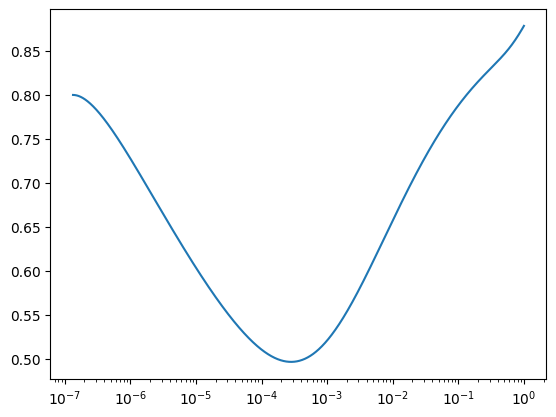

In [22]:
import matplotlib.pyplot as plt
plt.plot(asol, varpisol)
plt.xscale("log")

In [7]:
plt.plot(asol, constraint)

NameError: name 'constrain' is not defined

1.9307917635068308e-07
1.9307917635068308e-07
[np.float64(1.261606968617901e-07), np.float64(0.9900014997676475), np.float64(0.6534796452321086), np.float64(7.76662399134816)]
0.9999493555729108


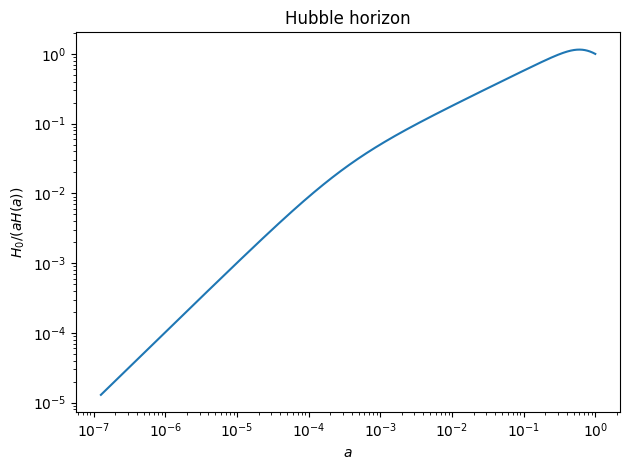

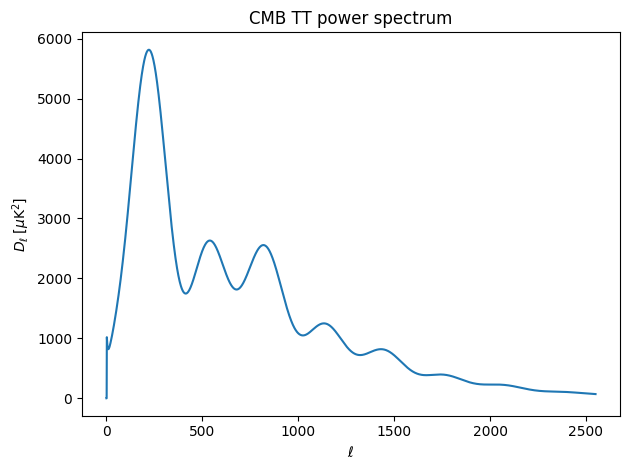

In [162]:
import camb
# --- Parameters ---
cpr     = 0.99
omega_m = 0.3
h       = 0.67
OmL     = 0.7
stigma  = 1.0
mups2   = 4/3
H0      = h * 100

# --- Solve ODE ---
asol, varpisol, hsol, dvarpisol, a0, P_DE, rho_DE, constrain = rhopsol(
    cpr, omega_m, h, OmL, stigma, mups2)

# --- Hubble horizon ---
plt.figure()
plt.plot(asol, H0*asol / (a0* hsol))
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$a$')
plt.ylabel(r'$H_0/(aH(a))$')
plt.title(r'Hubble horizon')
plt.tight_layout()
plt.show()

# --- CMB power spectrum ---
pars = camb.CAMBparams()
pars.set_cosmology(H0=H0, ombh2=0.02242, omch2=0.11933, mnu=0.06, omk=0, tau=0.0544)
pars.set_dark_energy_rho_p_a(a_p=asol, a_rho=asol, p=P_DE, rho=rho_DE)
pars.set_for_lmax(2500, lens_potential_accuracy=0)
pars.InitPower.set_params(As=2.1e-9, ns=0.965, r=0)

results = camb.get_results(pars)
cls = results.get_cmb_power_spectra(pars, CMB_unit='muK')['total']
ell = np.arange(cls.shape[0])

plt.figure()
plt.plot(ell, cls[:, 0])
plt.xlabel(r'$\ell$')
plt.ylabel(r'$D_\ell\;[\mu\mathrm{K}^2]$')
plt.title('CMB TT power spectrum')
plt.tight_layout()
plt.show()


In [177]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import camb

sys.path.insert(0, '/Users/starfish/Desktop/PhD2025-26/distances/TorC/Stigma/python')
from equations_double import rhopsol

# --- Fixed cosmological parameters ---
cpr     = 0.99
omega_m = 0.3
h       = 0.67
OmL     = 0.7
H0      = h * 100

def solve_and_camb(stigma, mups2):
    asol, _, hsol, _, a0, P_DE, rho_DE, constrain = rhopsol(
        cpr, omega_m, h, OmL, stigma, mups2)
    pars = camb.CAMBparams()
    pars.set_cosmology(H0=H0, ombh2=0.02242, omch2=0.11933, mnu=0.06, omk=0, tau=0.0544)
    pars.set_dark_energy_rho_p_a(a_p=asol, a_rho=asol, p=P_DE, rho=rho_DE)
    pars.set_for_lmax(2500, lens_potential_accuracy=0)
    pars.InitPower.set_params(As=2.1e-9, ns=0.965, r=0)
    results = camb.get_results(pars)
    cls = results.get_cmb_power_spectra(pars, CMB_unit='muK')['total']
    ell = np.arange(cls.shape[0])
    horizon = H0 * asol / (a0 * hsol)
    return asol, horizon, ell, cls[:, 0], constrain

In [180]:
# ======================================================
base_a, base_horizon, base_ell, base_cls, constrain_base = solve_and_camb(stigma=1.0, mups2=4/3)

1.9307917635068308e-07
1.9307917635068308e-07
[np.float64(1.261606968617901e-07), np.float64(0.9900014997676475), np.float64(0.6534796452321086), np.float64(7.76662399134816)]
0.9999493555729108


1.94921187357652e-07
1.94921187357652e-07
[np.float64(1.240382983393637e-07), np.float64(0.989993170022223), np.float64(0.6364146595809747), np.float64(-35.03720322532416)]
0.9801998379760737


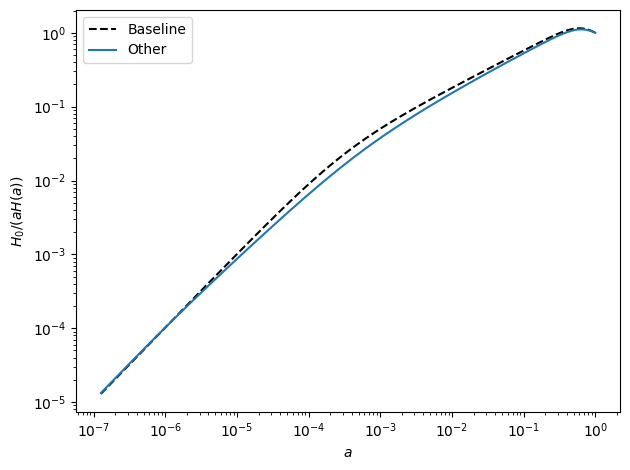

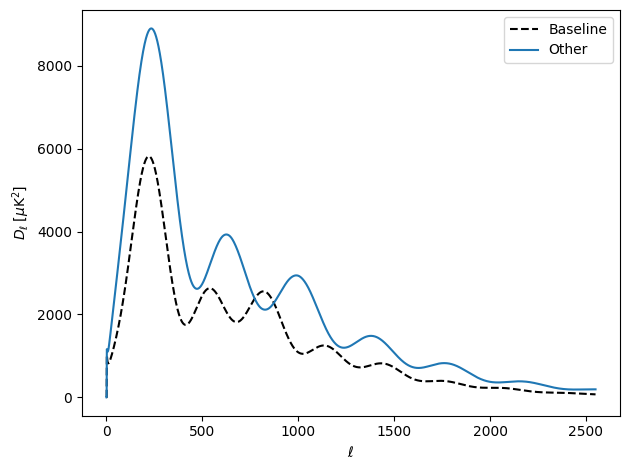

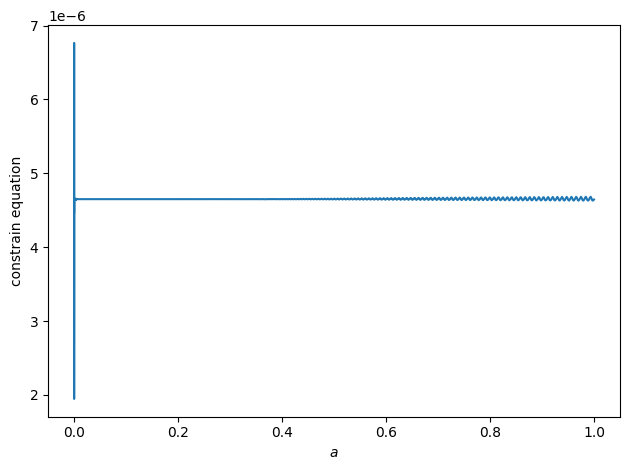

In [191]:
other_a, other_horizon, other_ell, other_cls, constrain = solve_and_camb(stigma=1.1062, mups2=4/3)

fig1, ax1 = plt.subplots()
ax1.plot(base_a,  base_horizon,  'k--', label='Baseline')
ax1.plot(other_a, other_horizon, '-',   label='Other')
ax1.set_xscale('log'); ax1.set_yscale('log')
ax1.set_xlabel(r'$a$'); ax1.set_ylabel(r'$H_0/(aH(a))$')
ax1.legend(); fig1.tight_layout()

fig2, ax2 = plt.subplots()
ax2.plot(base_ell,  base_cls,  'k--', label='Baseline')
ax2.plot(other_ell, other_cls, '-',   label='Other')
ax2.set_xlabel(r'$\ell$'); ax2.set_ylabel(r'$D_\ell\;[\mu\mathrm{K}^2]$')
ax2.legend(); fig2.tight_layout()

fig3, ax3 = plt.subplots()
ax3.plot(other_a, constrain, '-',   label='Other')
ax3.set_xlabel(r'$a$'); ax3.set_ylabel('constrain equation')
fig3.tight_layout()

plt.show()
